In [54]:
import os
import zipfile
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report,confusion_matrix,accuracy_score,precision_score,recall_score,f1_score)
from PIL import Image
import warnings
warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [55]:
zip_path = "PRCP-1001-RiceLeaf.zip"
extract_path = "RiceLeaf_Dataset"
os.makedirs(extract_path, exist_ok=True)
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    inner_files = [
        name for name in zip_ref.namelist()
        if name.endswith(".zip")
    ]
    for inner_file in inner_files:
        zip_ref.extract(inner_file, extract_path)
print("Dataset extracted successfully!")

Dataset extracted successfully!


In [56]:
classes = [
    "Leaf smut",
    "Brown spot",
    "Bacterial leaf blight"
]
data_path = "RiceLeaf_Dataset/Data"
for class_name in classes:
    class_zip = None
    for file in os.listdir(data_path):
        if file.startswith(class_name) and file.endswith(".zip"):
            class_zip = os.path.join(data_path, file)
            break
    if class_zip:
        output_folder = os.path.join(extract_path, class_name)
        os.makedirs(output_folder, exist_ok=True)
        with zipfile.ZipFile(class_zip, 'r') as zip_ref:
            for file in zip_ref.namelist():
                if file.lower().endswith((".jpg", ".jpeg", ".png")):
                    filename = os.path.basename(file)
                    output_file = os.path.join(output_folder, filename)
                    with open(output_file, "wb") as f:
                        f.write(zip_ref.read(file))
print("All disease images extracted successfully!")

All disease images extracted successfully!


## Task 1

In [57]:
dataset_path = "RiceLeaf_Dataset"
image_data = []
for class_name in classes:
    folder = os.path.join(dataset_path, class_name)
    for image in os.listdir(folder):
        if image.lower().endswith((".jpg", ".jpeg", ".png")):
            image_path = os.path.join(folder, image)
            try:
                img = Image.open(image_path)
                width, height = img.size
                image_data.append({
                    "Class": class_name,
                    "Image": image,
                    "Width": width,
                    "Height": height,
                    "Format": img.format
                })
            except Exception:
                print("Invalid image:", image_path)
df = pd.DataFrame(image_data)
print("Total Images:", len(df))
display(df.head())

Total Images: 119


,Class,Image,Width,Height,Format
0,Leaf smut,DSC_0293.JPG,3081,897,JPEG
1,Leaf smut,DSC_0308.JPG,3081,897,JPEG
2,Leaf smut,DSC_0309.JPG,3081,897,JPEG
3,Leaf smut,DSC_0310.JPG,3081,897,JPEG
4,Leaf smut,DSC_0312.JPG,3081,897,JPEG


In [58]:
print("Dataset Shape:", df.shape)

Dataset Shape: (119, 5)


In [59]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 119 entries, 0 to 118
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Class   119 non-null    str  
 1   Image   119 non-null    str  
 2   Width   119 non-null    int64
 3   Height  119 non-null    int64
 4   Format  119 non-null    str  
dtypes: int64(2), str(3)
memory usage: 4.8 KB


In [60]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Class     0
Image     0
Width     0
Height    0
Format    0
dtype: int64


In [61]:
print("Statistical Summary:")
display(df.describe())

Statistical Summary:


,Width,Height
count,119.000000,119.000000
mean,2383.638655,707.739496
std,1123.528972,311.657582
min,250.000000,71.000000
25%,1074.000000,377.000000
50%,3081.000000,897.000000
75%,3081.000000,897.000000
max,3081.000000,900.000000


Class
Brown spot               40
Bacterial leaf blight    40
Leaf smut                39
Name: count, dtype: int64


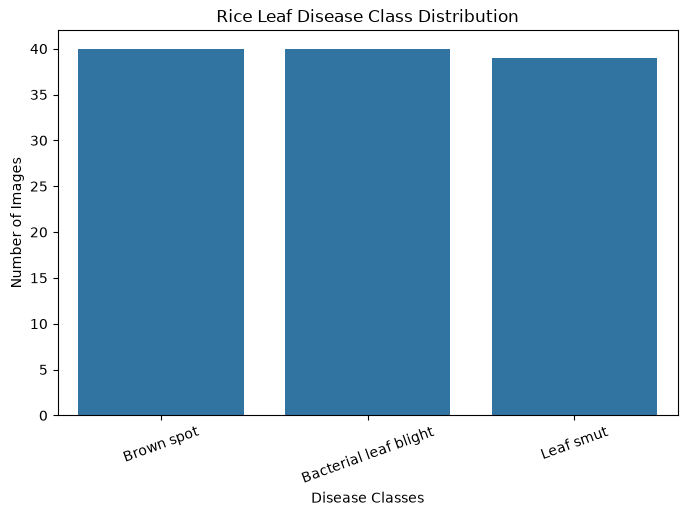

In [62]:
class_counts = df["Class"].value_counts()
print(class_counts)
plt.figure(figsize=(8, 5))
sns.barplot(x=class_counts.index,y=class_counts.values)
plt.title("Rice Leaf Disease Class Distribution")
plt.xlabel("Disease Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)
plt.show()

In [63]:
class_percentage = (df["Class"].value_counts(normalize=True) * 100)
display(class_percentage.round(2).to_frame(name="Percentage"))

,Percentage
Class,
Brown spot,33.61
Bacterial leaf blight,33.61
Leaf smut,32.77


Image Width Statistics:
count     119.000000
mean     2383.638655
std      1123.528972
min       250.000000
25%      1074.000000
50%      3081.000000
75%      3081.000000
max      3081.000000
Name: Width, dtype: float64

Image Height Statistics:
count    119.000000
mean     707.739496
std      311.657582
min       71.000000
25%      377.000000
50%      897.000000
75%      897.000000
max      900.000000
Name: Height, dtype: float64


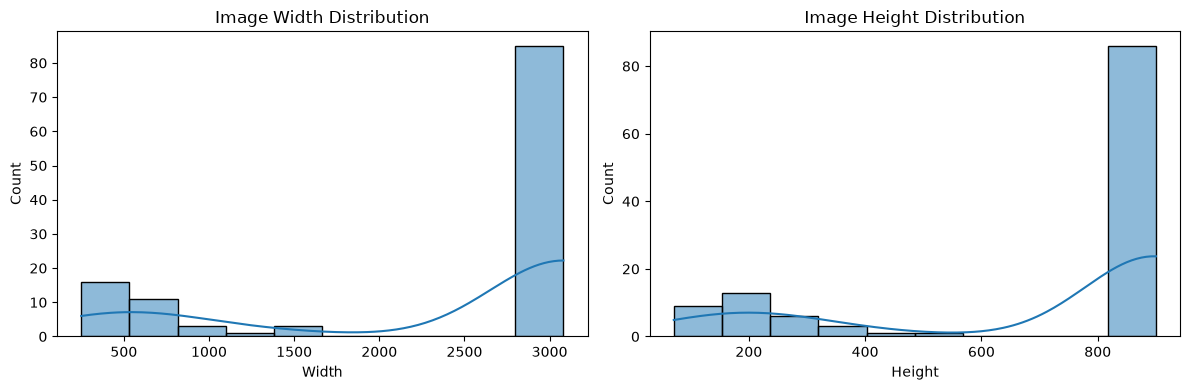

In [64]:
print("Image Width Statistics:")
print(df["Width"].describe())
print("\nImage Height Statistics:")
print(df["Height"].describe())
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(df["Width"], bins=10, kde=True)
plt.title("Image Width Distribution")
plt.subplot(1, 2, 2)
sns.histplot(df["Height"], bins=10, kde=True)
plt.title("Image Height Distribution")
plt.tight_layout()
plt.show()

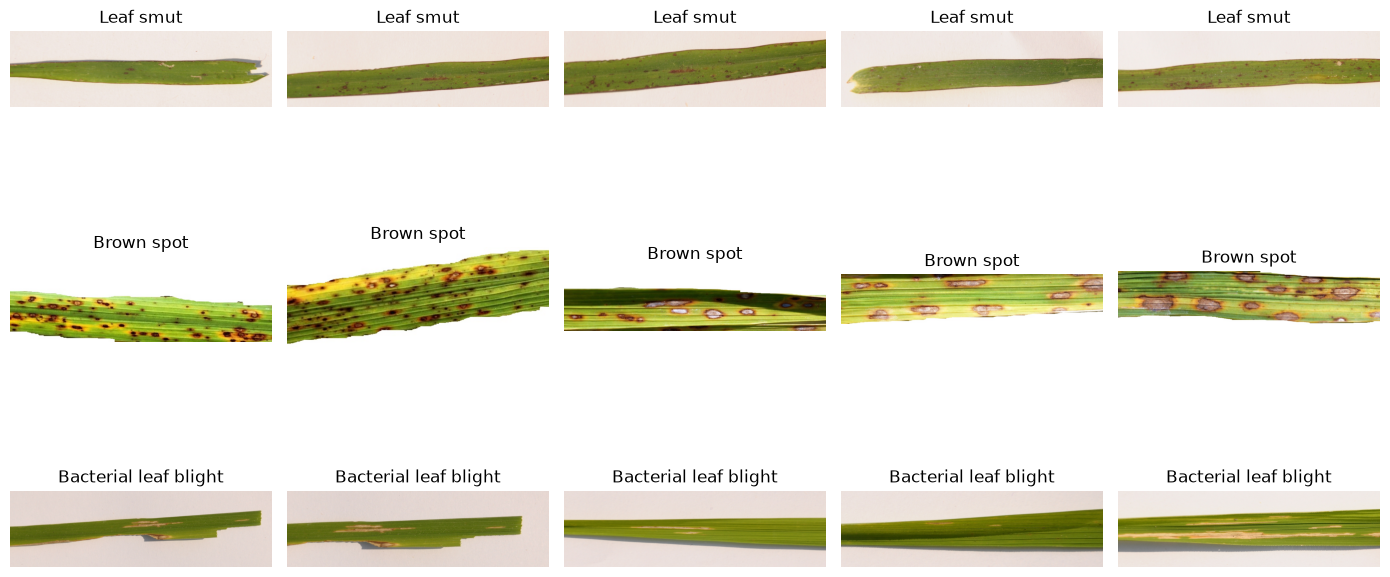

In [65]:
plt.figure(figsize=(14, 8))
for i, class_name in enumerate(classes):
    folder = os.path.join(dataset_path, class_name)
    images = os.listdir(folder)[:5]
    for j, image in enumerate(images):
        image_path = os.path.join(folder, image)
        img = Image.open(image_path)
        plt.subplot(3, 5, i * 5 + j + 1)
        plt.imshow(img)
        plt.title(class_name)
        plt.axis("off")
plt.tight_layout()
plt.show()

## TASK 1 – DATA ANALYSIS CONCLUSION

1. The dataset contains three rice leaf disease classes: **Leaf Smut, Brown Spot, and Bacterial Leaf Blight**.
2. The dataset consists of approximately **119 images**.
3. The class distribution is almost balanced across all three categories.
4. Image dimensions and file formats were analyzed.
5. Sample images were visualized to understand the characteristics and patterns of each disease.
6. The dataset is suitable for image classification after preprocessing and resizing.

**Conclusion:** The data analysis provides a clear understanding of the dataset, its class distribution, image properties, and disease patterns. The dataset is ready for the next stage of image preprocessing and model development.

## Task 2

In [66]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 8
image_paths = []
labels = []
for label, class_name in enumerate(classes):
    folder = os.path.join(dataset_path, class_name)
    for image in os.listdir(folder):
        if image.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(os.path.join(folder, image))
            labels.append(label)
image_paths = np.array(image_paths)
labels = np.array(labels)
print("Total Images:", len(image_paths))
print("Total Classes:", len(classes))

Total Images: 119
Total Classes: 3


In [67]:
X_train, X_temp, y_train, y_temp = train_test_split(image_paths,labels,test_size=0.30,random_state=SEED,stratify=labels)
X_val, X_test, y_val, y_test = train_test_split(X_temp,y_temp,test_size=0.50,random_state=SEED,stratify=y_temp)
print("Training Images:", len(X_train))
print("Validation Images:", len(X_val))
print("Testing Images:", len(X_test))

Training Images: 83
Validation Images: 18
Testing Images: 18


In [68]:
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image,channels=3,expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image,IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label
def create_dataset(paths, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        dataset = dataset.shuffle(len(paths),seed=SEED)
    dataset = dataset.map(load_image,num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset
train_ds = create_dataset(X_train, y_train, training=True)
val_ds = create_dataset(X_val, y_val)
test_ds = create_dataset(X_test, y_test)
print("Image preprocessing completed!")

Image preprocessing completed!


In [69]:
base_model = keras.applications.MobileNetV2(input_shape=(224, 224, 3),include_top=False,weights="imagenet")
base_model.trainable = False
model = keras.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Lambda(keras.applications.mobilenet_v2.preprocess_input),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128,activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(3,activation="softmax")
])
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lambda_2 (Lambda)                    │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_2           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [70]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss",patience=5,restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss",factor=0.2,patience=2)
]
history = model.fit(train_ds,validation_data=val_ds,epochs=20,callbacks=callbacks)

Epoch 1/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 18s 906ms/step - accuracy: 0.4337 - loss: 1.7557 - val_accuracy: 0.6667 - val_loss: 0.8754 - learning_rate: 0.0010
Epoch 2/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 265ms/step - accuracy: 0.7470 - loss: 0.5998 - val_accuracy: 0.8889 - val_loss: 0.4308 - learning_rate: 0.0010
Epoch 3/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 245ms/step - accuracy: 0.9036 - loss: 0.3374 - val_accuracy: 0.9444 - val_loss: 0.2753 - learning_rate: 0.0010
Epoch 4/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 246ms/step - accuracy: 0.9157 - loss: 0.1687 - val_accuracy: 0.9444 - val_loss: 0.2169 - learning_rate: 0.0010
Epoch 5/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 397ms/step - accuracy: 0.9398 - loss: 0.1399 - val_accuracy: 0.9444 - val_loss: 0.2060 - learning_rate: 0.0010
Epoch 6/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 285ms/step - accuracy: 0.9398 - loss: 0.1538 - val_accuracy: 0.9444 - val_loss: 0.2424 - learning_rate: 0.0010
Epoch 7/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 266ms/step - accuracy: 1.0000 - loss: 0.0631 -

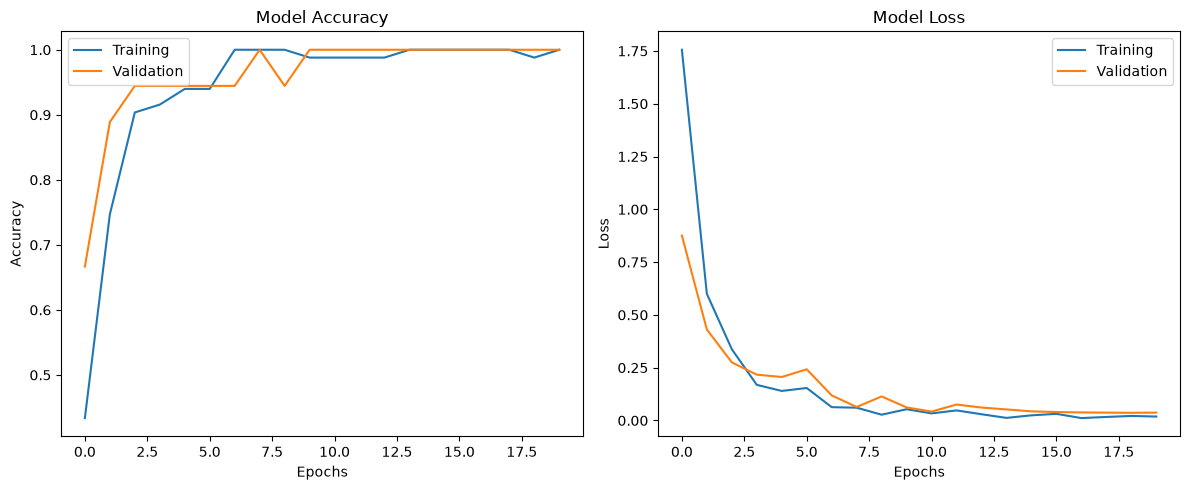

In [71]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

In [72]:
test_loss, test_accuracy = model.evaluate(test_ds)
print("Test Loss:", test_loss)
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 131ms/step - accuracy: 1.0000 - loss: 0.0617
Test Loss: 0.06174837052822113
Test Accuracy: 100.0 %


In [73]:
y_pred_prob = model.predict(test_ds)
y_pred = np.argmax(y_pred_prob,axis=1)
print(
    classification_report(y_test,y_pred,target_names=classes,zero_division=0)
)

2/3 ━━━━━━━━━━━━━━━━━━━━ 0s 317ms/stepWARNING:tensorflow:6 out of the last 12 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x000002382798FA60> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step
                       precision    recall  f1-score   support

            Leaf smut       1.00      1.00      1.00         6
           Brown spot       1.00      1.00      1.00         6
Bacterial

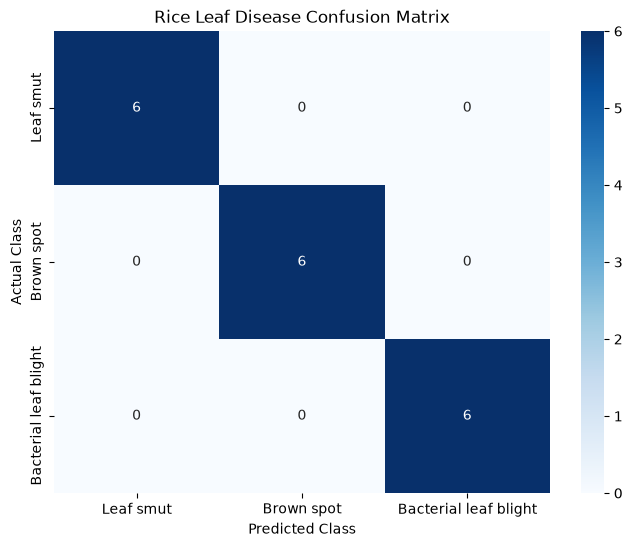

In [74]:
cm = confusion_matrix(y_test,y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)
plt.title("Rice Leaf Disease Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [75]:
model.save("RiceLeaf_Disease_Detection_Model.keras")
print("Model saved successfully!")

Model saved successfully!


## TASK 2 - MODEL DEVELOPMENT CONCLUSION

- Developed a deep learning model to classify three types of rice leaf diseases.
- The three disease classes are **Leaf smut, Brown spot, and Bacterial leaf blight**.
- Used **MobileNetV2 Transfer Learning** for image classification.
- Divided the dataset into training, validation, and testing sets.
- Evaluated model performance using accuracy, precision, recall, and F1-score.
- Generated a confusion matrix and classification report to analyze prediction performance.
- Saved the trained model for future predictions.

**Conclusion:** The developed deep learning model provides an automated approach to identifying rice leaf diseases from images.

## Task 3

In [76]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10)
])
print("Data augmentation techniques initialized!")

Data augmentation techniques initialized!


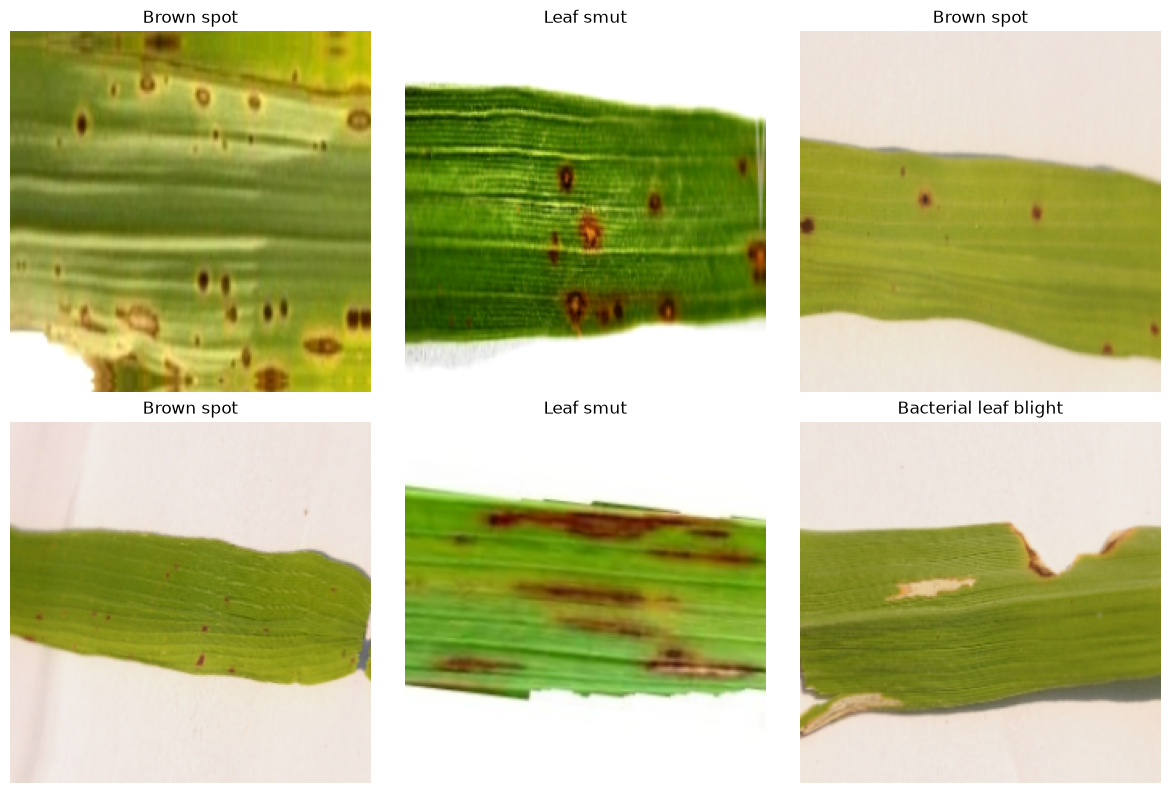

In [77]:
sample_images, sample_labels = next(iter(train_ds))
plt.figure(figsize=(12, 8))
for i in range(6):
    augmented_image = data_augmentation(sample_images[i:i+1],training=True)
    plt.subplot(2, 3, i + 1)
    plt.imshow(tf.cast(tf.clip_by_value(augmented_image[0], 0, 255),tf.uint8))
    plt.title(classes[int(sample_labels[i])])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [78]:
aug_base_model = keras.applications.MobileNetV2(input_shape=(224, 224, 3),include_top=False,weights="imagenet")
aug_base_model.trainable = False
aug_model = keras.Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Lambda(keras.applications.mobilenet_v2.preprocess_input),
    aug_base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128,activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(3,activation="softmax")
])
aug_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
aug_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential_4 (Sequential)            │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lambda_3 (Lambda)                    │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_3           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [79]:
aug_history = aug_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss",patience=5,restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss",factor=0.2,patience=2)
    ]
)

Epoch 1/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 15s 552ms/step - accuracy: 0.5301 - loss: 1.0314 - val_accuracy: 0.6667 - val_loss: 0.7180 - learning_rate: 0.0010
Epoch 2/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 300ms/step - accuracy: 0.7711 - loss: 0.5509 - val_accuracy: 0.8889 - val_loss: 0.2779 - learning_rate: 0.0010
Epoch 3/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 254ms/step - accuracy: 0.8072 - loss: 0.4285 - val_accuracy: 0.9444 - val_loss: 0.2705 - learning_rate: 0.0010
Epoch 4/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 252ms/step - accuracy: 0.9036 - loss: 0.2827 - val_accuracy: 0.9444 - val_loss: 0.2109 - learning_rate: 0.0010
Epoch 5/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 277ms/step - accuracy: 0.9398 - loss: 0.1668 - val_accuracy: 0.8333 - val_loss: 0.3046 - learning_rate: 0.0010
Epoch 6/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 269ms/step - accuracy: 0.9398 - loss: 0.1952 - val_accuracy: 0.9444 - val_loss: 0.1892 - learning_rate: 0.0010
Epoch 7/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 254ms/step - accuracy: 0.9036 - loss: 0.1843 -

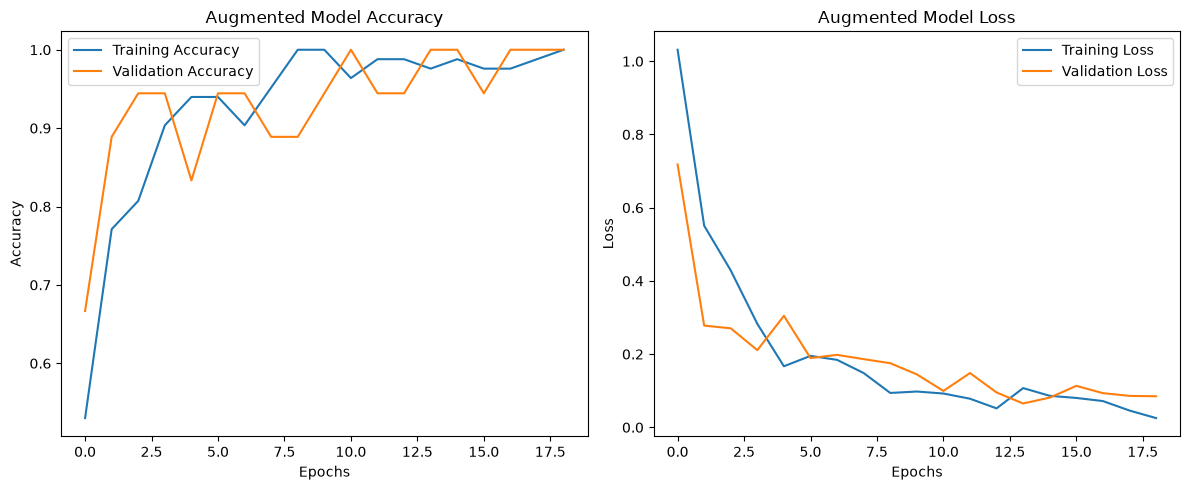

In [80]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(aug_history.history["accuracy"],label="Training Accuracy")
plt.plot(aug_history.history["val_accuracy"],label="Validation Accuracy")
plt.title("Augmented Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(aug_history.history["loss"],label="Training Loss")
plt.plot(aug_history.history["val_loss"],label="Validation Loss")
plt.title("Augmented Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

In [81]:
aug_loss, aug_accuracy = aug_model.evaluate(test_ds)
print("Augmented Model Test Loss:", aug_loss)
print("Augmented Model Test Accuracy:",round(aug_accuracy * 100, 2),"%")

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 130ms/step - accuracy: 1.0000 - loss: 0.0662
Augmented Model Test Loss: 0.06617097556591034
Augmented Model Test Accuracy: 100.0 %


In [82]:
baseline_pred = np.argmax(model.predict(test_ds),axis=1)
augmented_pred = np.argmax(aug_model.predict(test_ds),axis=1)
comparison = pd.DataFrame({
    "Model": [
        "MobileNetV2 Baseline",
        "MobileNetV2 with Augmentation"
    ],
    "Accuracy": [
        accuracy_score(y_test, baseline_pred),
        accuracy_score(y_test, augmented_pred)
    ],
    "Precision": [
        precision_score(y_test, baseline_pred,average="macro", zero_division=0),
        precision_score(y_test, augmented_pred,average="macro", zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, baseline_pred,average="macro", zero_division=0),
        recall_score(y_test, augmented_pred,average="macro", zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, baseline_pred,average="macro", zero_division=0),
        f1_score(y_test, augmented_pred,average="macro", zero_division=0)
    ]
})
display(comparison.round(4))

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 132ms/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step


,Model,Accuracy,Precision,Recall,F1 Score
0,MobileNetV2 Baseline,1.0,1.0,1.0,1.0
1,MobileNetV2 with Augmentation,1.0,1.0,1.0,1.0


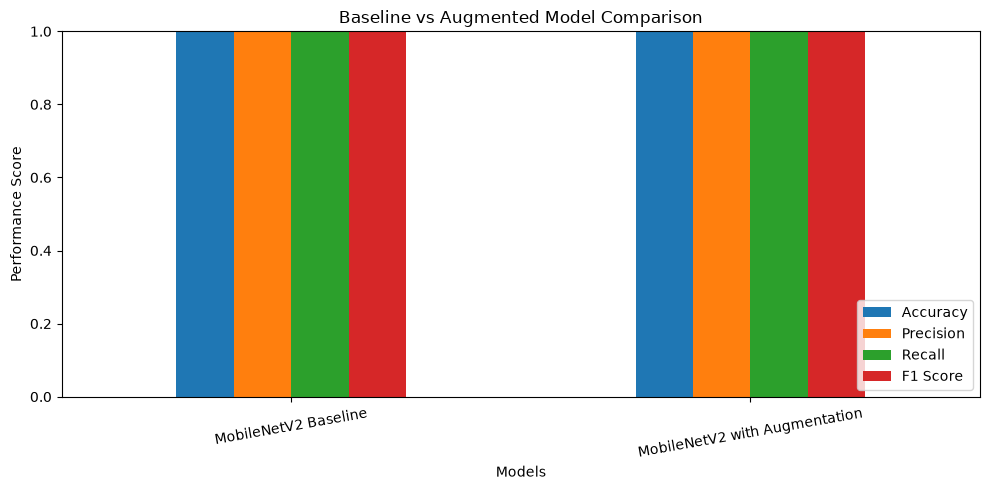

In [83]:
comparison.set_index("Model").plot(kind="bar",figsize=(10, 5),ylim=(0, 1))
plt.title("Baseline vs Augmented Model Comparison")
plt.ylabel("Performance Score")
plt.xlabel("Models")
plt.xticks(rotation=10)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [84]:
best_model_name = comparison.loc[comparison["F1 Score"].idxmax(),"Model"]
print("Best Performing Model:", best_model_name)
if best_model_name == "MobileNetV2 Baseline":
    print("The baseline model achieved the highest F1 score.")
else:
    print("The augmented model achieved the highest F1 score.")

Best Performing Model: MobileNetV2 Baseline
The baseline model achieved the highest F1 score.


In [85]:
aug_model.save("RiceLeaf_Augmented_Model.keras")
comparison.to_csv("RiceLeaf_Model_Comparison.csv",index=False)
print("Augmented model saved successfully!")
print("Comparison report saved successfully!")

Augmented model saved successfully!
Comparison report saved successfully!


In [86]:
def predict_disease(image_path):
    img = keras.utils.load_img(image_path,target_size=(224, 224))
    img_array = keras.utils.img_to_array(img)
    img_array = np.expand_dims(img_array,axis=0)
    prediction = aug_model.predict(img_array)
    predicted_class = np.argmax(prediction)
    confidence = np.max(prediction) * 100
    plt.imshow(img)
    plt.title(
        f"Predicted: {classes[predicted_class]}\n"
        f"Confidence: {confidence:.2f}%"
    )
    plt.axis("off")
    plt.show()
    print("Predicted Disease:", classes[predicted_class])
    print("Confidence:", round(confidence, 2), "%")

## TASK 3 - DATA AUGMENTATION CONCLUSION

- Applied data augmentation techniques to increase training image diversity.
- Used techniques such as **rotation, flipping, zooming, and contrast adjustment**.
- Trained a model using augmented images.
- Compared the original model with the augmented model.
- Evaluated both models using accuracy, precision, recall, and F1-score.
- Analyzed the impact of augmentation on model generalization and overfitting.

**Conclusion:** Data augmentation introduces variations into training images and can improve the model's ability to generalize to unseen images. The comparison helps determine its impact on rice leaf disease classification.

# MODEL COMPARISON REPORT

## Objective
The objective of this comparison is to evaluate the performance of different models for rice leaf disease classification and identify the most suitable model for production.

## Models Evaluated

1. **MobileNetV2 (Baseline Model):** Used transfer learning with pretrained ImageNet weights to classify rice leaf diseases.
2. **MobileNetV2 with Data Augmentation:** Used rotation, flipping, zooming, and contrast adjustment to improve training image diversity.

## Evaluation Metrics

The models were evaluated using the following metrics:

- **Accuracy:** Measures the overall percentage of correct predictions.
- **Precision:** Measures how many predicted disease classes were correct.
- **Recall:** Measures how effectively the model identifies actual disease classes.
- **F1-Score:** Represents the balance between precision and recall.

## Model Performance Comparison

The baseline and augmented models were compared using their test dataset results. The comparison considered accuracy, precision, recall, and F1-score.

## Production Recommendation

MobileNetV2 is a suitable candidate for production because it uses transfer learning, requires comparatively fewer computational resources, and is suitable for image classification applications.

The final production model should be selected based on the actual test results. If the augmented model achieves better or comparable performance with improved generalization, it can be preferred.

## Conclusion

Both models provide an approach for automated rice leaf disease classification. Model comparison helps identify a suitable model based on prediction performance, generalization, and computational efficiency.

# REPORT ON CHALLENGES FACED

During the Rice Leaf Disease Detection project, several challenges were encountered during data preparation, model development, and evaluation.

## 1. Dataset Organization

**Challenge:** The dataset was provided in multiple ZIP files containing images belonging to different disease categories.

**Technique Used:** Python ZIP extraction and directory organization.

**Reason:** To extract and organize images into separate class folders for easier processing and classification.

## 2. Limited Dataset Size

**Challenge:** The dataset contained only 119 images across three disease classes.

**Technique Used:** Data augmentation techniques such as rotation, flipping, zooming, and contrast adjustment.

**Reason:** To introduce image variations, increase training diversity, and help reduce overfitting.

## 3. Image Preprocessing

**Challenge:** Images had different dimensions and needed to be converted into a consistent format.

**Technique Used:** Image resizing, normalization/preprocessing, and batching.

**Reason:** To provide consistent image inputs to the deep learning model.

## 4. Model Training with Limited Data

**Challenge:** Training a deep learning model from a small dataset can lead to overfitting and poor generalization.

**Technique Used:** MobileNetV2 transfer learning with pretrained ImageNet weights.

**Reason:** To reuse previously learned image features and reduce the need for training a large model from scratch.

## 5. Model Performance Evaluation

**Challenge:** Accuracy alone does not provide complete information about classification performance.

**Technique Used:** Confusion matrix, classification report, precision, recall, and F1-score.

**Reason:** To evaluate the model's ability to identify each disease class and understand misclassifications.

## 6. TensorFlow Environment Issues

**Challenge:** TensorFlow installation and compatibility issues occurred in the Python environment during model development.

**Technique Used:** Package version checking, dependency management, and separate Python environment setup.

**Reason:** To maintain a compatible environment and ensure reliable execution of the deep learning code.

## Overall Conclusion

The project challenges were addressed using image preprocessing, data augmentation, transfer learning, and appropriate evaluation techniques. These methods helped establish a structured workflow for rice leaf disease classification and model performance analysis.